# Проверка библиотек и импорты

In [18]:
import importlib

libs = {
    'torch':        'PyTorch',
    'torchvision':  'TorchVision',
    'ultralytics':  'Ultralytics (YOLOv8)',
    'cv2':          'OpenCV',
    'matplotlib':   'Matplotlib',
    'numpy':        'NumPy',
    'PIL':          'Pillow',
    'pandas':       'Pandas',
}

for pkg, name in libs.items():
    try:
        mod = importlib.import_module(pkg)
        ver = getattr(mod, '__version__', '?')
        print(f'[OK]  {name}: {ver}')
    except ImportError:
        print(f'[НЕТ] {name}: установите через pip')

[OK]  PyTorch: 2.2.2+rocm5.7
[OK]  TorchVision: 0.17.2+rocm5.7
[OK]  Ultralytics (YOLOv8): 8.4.182
[OK]  OpenCV: 4.10.0
[OK]  Matplotlib: 3.9.0
[OK]  NumPy: 1.26.4
[OK]  Pillow: 12.3.0
[OK]  Pandas: 2.2.2


In [19]:
import os, shutil, time, urllib.request
from pathlib import Path
import numpy as np, cv2, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
from torchvision.ops import box_iou
from ultralytics import YOLO, settings
from ultralytics.utils.downloads import safe_download

DATA = Path('./lab4_data').resolve()
IMG = DATA / 'images'
IMG.mkdir(parents=True, exist_ok=True)
settings.update({'datasets_dir': str(DATA)})

device = torch.device('cpu')
print('device:', device)

device: cpu


# Подготовка изображений

In [20]:
urls = [
    ('https://ultralytics.com/images/bus.jpg', '01_bus.jpg'),
    ('https://ultralytics.com/images/zidane.jpg', '02_zidane.jpg'),
    ('https://images.unsplash.com/photo-1552053831-71594a27632d?w=800&q=80', '03_dog.jpg'),
    ('https://images.unsplash.com/photo-1514888286974-6c03e2ca1dba?w=800&q=80', '04_cat.jpg'),
    ('https://images.unsplash.com/photo-1494976388531-d1058494cdd8?w=800&q=80', '05_car.jpg'),
    ('https://images.unsplash.com/photo-1485965120184-e220f721d03e?w=800&q=80', '06_bike.jpg'),
    ('https://images.unsplash.com/photo-1494790108377-be9c29b29330?w=800&q=80', '07_person.jpg'),
    ('https://images.unsplash.com/photo-1517649763962-0c623066013b?w=800&q=80', '08_cycling.jpg'),
    ('https://images.unsplash.com/photo-1557804506-669a67965ba0?w=800&q=80', '09_office.jpg'),
    ('https://images.unsplash.com/photo-1542291026-7eec264c27ff?w=800&q=80', '10_shoes.jpg'),
]

def dl(url, out):
    try:
        req = urllib.request.Request(url, headers={'User-Agent':'Mozilla/5.0'})
        with urllib.request.urlopen(req, timeout=20) as r:
            out.write_bytes(r.read())
        return cv2.imread(str(out)) is not None
    except Exception as e:
        print('skip', e)
        return False

bad = []
for u, n in urls:
    p = IMG / n
    if p.exists():
        print('have', n)
        continue
    if dl(u, p):
        print('ok', n)
    else:
        print('fail', n)
        bad.append(n)

if bad:
    print('take from coco128')
    c = DATA / 'coco128'
    if not (c / 'images').exists():
        safe_download(url='https://github.com/ultralytics/assets/releases/download/v0.0.0/coco128.zip',
                      dir=DATA, unzip=True)
    pool = sorted((c / 'images' / 'train2017').glob('*.jpg'))[:len(bad)]
    for n, s in zip(bad, pool):
        shutil.copy(s, IMG / n)
        print(n, '<-', s.name)

image_paths = sorted(IMG.glob('*.jpg'))[:10]
print('images:', len(image_paths))
for p in image_paths:
    print(p.name)

have 01_bus.jpg
have 02_zidane.jpg
have 03_dog.jpg
have 04_cat.jpg
have 05_car.jpg
have 06_bike.jpg
have 07_person.jpg
have 08_cycling.jpg
have 09_office.jpg
have 10_shoes.jpg
images: 10
01_bus.jpg
02_zidane.jpg
03_dog.jpg
04_cat.jpg
05_car.jpg
06_bike.jpg
07_person.jpg
08_cycling.jpg
09_office.jpg
10_shoes.jpg


# Инференс и визуализация результатов детекции

In [21]:
model = YOLO('yolov8n.pt')
IMG_SIZE = 320
CONF_THR = 0.25

results = model.predict(source=[str(p) for p in image_paths],
                        imgsz=IMG_SIZE, conf=CONF_THR, verbose=False)

detections = {}
for path, r in zip(image_paths, results):
    lst = []
    if r.boxes is not None and len(r.boxes) > 0:
        xyxy = r.boxes.xyxy.cpu().numpy()
        cf = r.boxes.conf.cpu().numpy()
        cl = r.boxes.cls.cpu().numpy().astype(int)
        for i in range(len(cl)):
            lst.append((model.names[cl[i]], float(cf[i]), xyxy[i]))
    detections[path.name] = lst
    print(path.name, 'objects:', len(lst))
    for c, p, _ in lst:
        print(' ', c, round(p, 2))

summary = pd.DataFrame([
    {'image': n, 'n_objects': len(d), 'classes': ', '.join(sorted({c for c, _, _ in d}))}
    for n, d in detections.items()
])
summary

01_bus.jpg objects: 4
  person 0.85
  bus 0.84
  person 0.75
  person 0.69
02_zidane.jpg objects: 2
  person 0.82
  person 0.8
03_dog.jpg objects: 1
  dog 0.9
04_cat.jpg objects: 1
  cat 0.85
05_car.jpg objects: 1
  car 0.95
06_bike.jpg objects: 1
  bicycle 0.95
07_person.jpg objects: 1
  person 0.95
08_cycling.jpg objects: 18
  person 0.73
  person 0.72
  bicycle 0.52
  person 0.47
  person 0.44
  person 0.44
  bicycle 0.44
  bicycle 0.43
  bicycle 0.36
  bicycle 0.35
  bicycle 0.33
  bicycle 0.32
  person 0.32
  bicycle 0.31
  bicycle 0.29
  bicycle 0.28
  bicycle 0.27
  bicycle 0.26
09_office.jpg objects: 5
  person 0.89
  person 0.81
  person 0.74
  laptop 0.71
  person 0.66
10_shoes.jpg objects: 0


,image,n_objects,classes
0,01_bus.jpg,4,"bus, person"
1,02_zidane.jpg,2,person
2,03_dog.jpg,1,dog
3,04_cat.jpg,1,cat
4,05_car.jpg,1,car
5,06_bike.jpg,1,bicycle
6,07_person.jpg,1,person
7,08_cycling.jpg,18,"bicycle, person"
8,09_office.jpg,5,"laptop, person"
9,10_shoes.jpg,0,


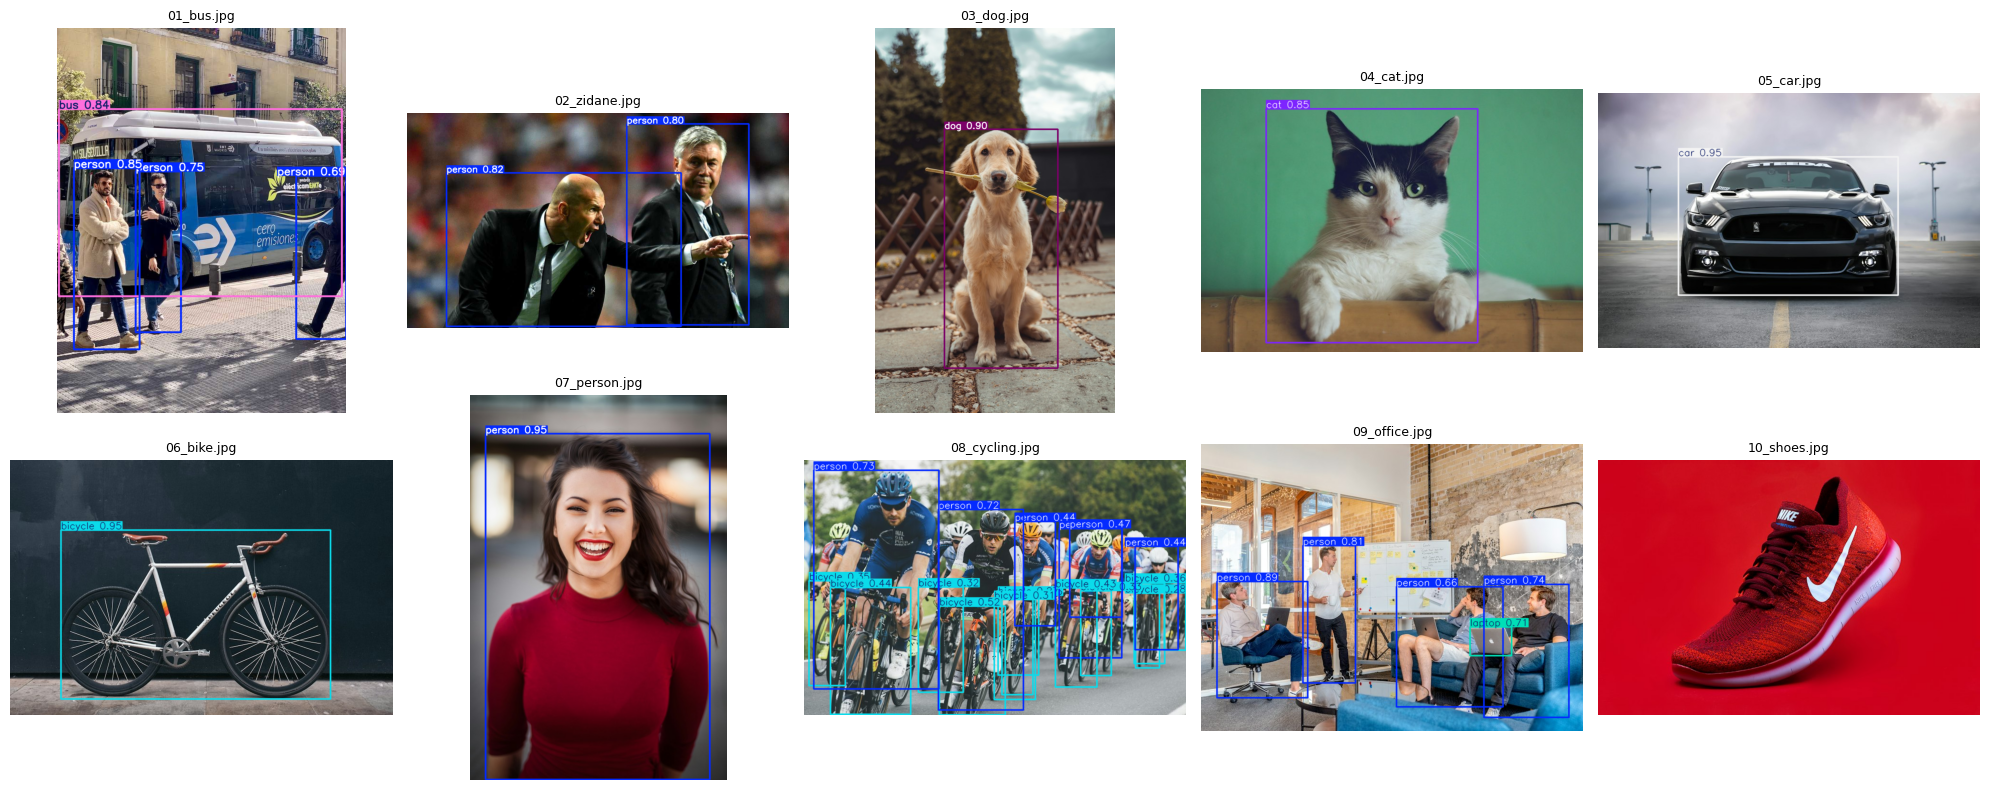

In [22]:
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
for ax, r in zip(axes.flat, results):
    ax.imshow(r.plot()[:, :, ::-1])
    ax.set_title(Path(r.path).name, fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()

# Ground truth для 3 картинок

In [23]:
gt_rel = {
    '01_bus.jpg': [
        (0.04, 0.38, 0.13, 0.86, 'person'),
        (0.14, 0.37, 0.24, 0.86, 'person'),
        (0.28, 0.38, 0.44, 0.84, 'person'),
        (0.83, 0.35, 0.99, 0.81, 'person'),
        (0.01, 0.21, 0.99, 0.71, 'bus'),
    ],
    '02_zidane.jpg': [
        (0.10, 0.28, 0.60, 0.97, 'person'),
        (0.59, 0.06, 0.91, 0.97, 'person'),
    ],
    '04_cat.jpg': [
        (0.15, 0.09, 0.83, 0.96, 'cat'),
    ],
}
def iou(a, b):
    x1 = max(a[0], b[0]); y1 = max(a[1], b[1])
    x2 = min(a[2], b[2]); y2 = min(a[3], b[3])
    inter = max(0.0, x2 - x1) * max(0.0, y2 - y1)
    u = (a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - inter
    return inter / u if u > 0 else 0.0

gt_pixels = {}
for name, rel in gt_rel.items():
    img = cv2.imread(str(IMG / name))
    if img is None:
        print('no file', name); continue
    h, w = img.shape[:2]
    gt_pixels[name] = [(r[0]*w, r[1]*h, r[2]*w, r[3]*h, r[4]) for r in rel]

rows = []
for name, gt in gt_pixels.items():
    preds = detections.get(name, [])
    for j, g in enumerate(gt):
        best, bp = 0.0, None
        for c, p, pb in preds:
            v = iou(pb, g[:4])
            if v > best:
                best, bp = v, (c, p, pb)
        rows.append({
            'image': name,
            'gt_idx': j + 1,
            'gt_class': g[4],
            'gt_bbox': tuple(round(x) for x in g[:4]),
            'pred_class': bp[0] if bp else '-',
            'pred_conf': round(bp[1], 2) if bp else None,
            'pred_bbox': tuple(round(x) for x in bp[2]) if bp else '-',
            'IoU': round(best, 3),
        })

iou_table = pd.DataFrame(rows).sort_values(['image', 'gt_idx']).reset_index(drop=True)
iou_table

,image,gt_idx,gt_class,gt_bbox,pred_class,pred_conf,pred_bbox,IoU
0,01_bus.jpg,1,person,"(32, 410, 105, 929)",person,0.85,"(47, 394, 231, 901)",0.276
1,01_bus.jpg,2,person,"(113, 400, 194, 929)",person,0.85,"(47, 394, 231, 901)",0.426
2,01_bus.jpg,3,person,"(227, 410, 356, 907)",person,0.75,"(220, 403, 348, 854)",0.786
3,01_bus.jpg,4,person,"(672, 378, 802, 875)",person,0.69,"(670, 415, 810, 872)",0.858
4,01_bus.jpg,5,bus,"(8, 227, 802, 767)",bus,0.84,"(5, 228, 798, 753)",0.964
5,02_zidane.jpg,1,person,"(128, 202, 768, 698)",person,0.82,"(133, 201, 918, 715)",0.777
6,02_zidane.jpg,2,person,"(755, 43, 1165, 698)",person,0.80,"(737, 36, 1145, 709)",0.888
7,04_cat.jpg,1,cat,"(120, 50, 664, 528)",cat,0.85,"(136, 42, 579, 530)",0.801


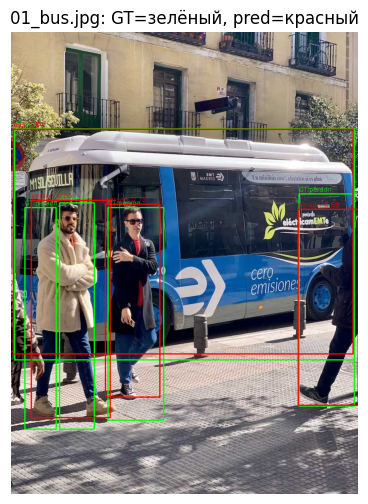

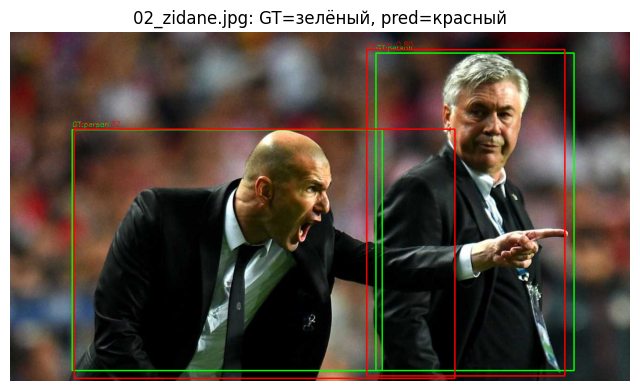

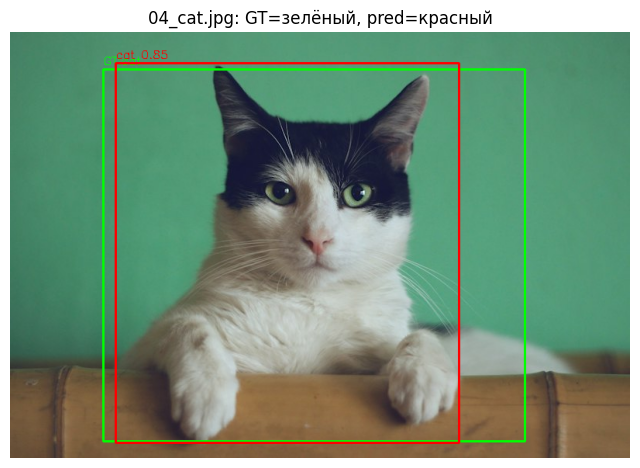

In [24]:
for name, gt in gt_pixels.items():
    img = cv2.imread(str(IMG / name))
    vis = img.copy()
    for g in gt:
        x1, y1, x2, y2 = map(int, g[:4])
        cv2.rectangle(vis, (x1, y1), (x2, y2), (0, 255, 0), 2)
        cv2.putText(vis, f'GT:{g[4]}', (x1, max(y1 - 6, 12)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 1)
    for c, p, b in detections.get(name, []):
        x1, y1, x2, y2 = map(int, b)
        cv2.rectangle(vis, (x1, y1), (x2, y2), (0, 0, 255), 2)
        cv2.putText(vis, f'{c} {p:.2f}', (x1, max(y1 - 6, 12)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 1)
    plt.figure(figsize=(8, 6))
    plt.imshow(vis[:, :, ::-1])
    plt.title(f'{name}: GT=зелёный, pred=красный')
    plt.axis('off')
    plt.show()

# Анализ False Positives (FP) и False Negatives (FN)

In [25]:
def match_detections(pred_boxes, gt_boxes, iou_threshold=0.5):
    if not pred_boxes or not gt_boxes:
        return [], list(range(len(pred_boxes))), list(range(len(gt_boxes)))
    M = box_iou(torch.tensor(pred_boxes, dtype=torch.float32),
                torch.tensor(gt_boxes, dtype=torch.float32)).numpy()
    pairs = sorted(((M[i, j], i, j) for i in range(M.shape[0]) for j in range(M.shape[1])),
                   reverse=True)
    mp, mg, tp = set(), set(), []
    for v, i, j in pairs:
        if v < iou_threshold:
            break
        if i in mp or j in mg:
            continue
        tp.append((i, j, float(v))); mp.add(i); mg.add(j)
    fp = [i for i in range(len(pred_boxes)) if i not in mp]
    fn = [j for j in range(len(gt_boxes)) if j not in mg]
    return tp, fp, fn

In [26]:
fp_fn_report = {}
for name, gt in gt_pixels.items():
    preds = detections.get(name, [])
    pb = [list(p[2]) for p in preds]
    pl = [p[0] for p in preds]
    gb = [list(g[:4]) for g in gt]
    gl = [g[4] for g in gt]
    tp, fp, fn = match_detections(pb, gb, 0.5)
    fp_fn_report[name] = {'tp': tp, 'fp': fp, 'fn': fn,
                          'preds': preds, 'gl': gl, 'gb': gb}
    print()
    print(name)
    print('tp', len(tp), 'fp', len(fp), 'fn', len(fn))
    for i in fp:
        print(' fp:', pl[i], round(preds[i][1], 2))
    for j in fn:
        print(' fn:', gl[j])


01_bus.jpg
tp 3 fp 1 fn 2
 fp: person 0.85
 fn: person
 fn: person

02_zidane.jpg
tp 2 fp 0 fn 0

04_cat.jpg
tp 1 fp 0 fn 0


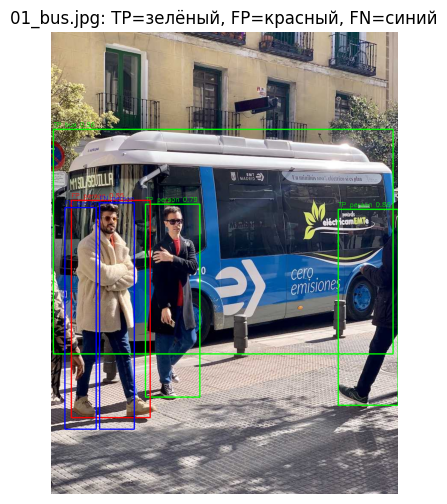

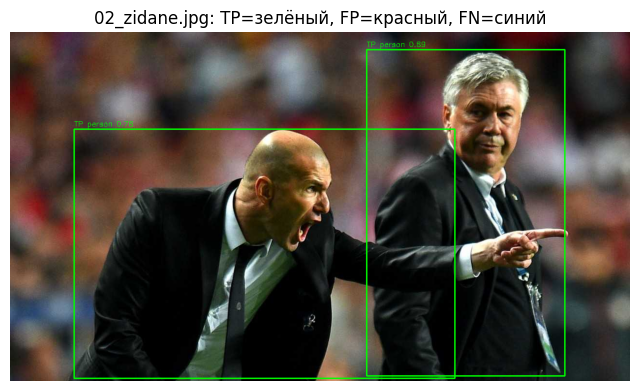

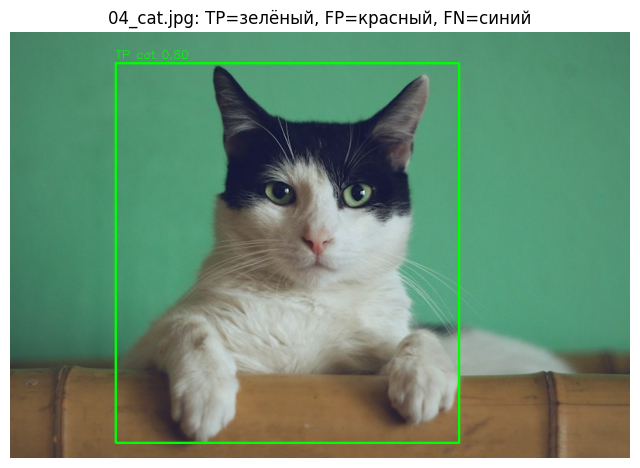

In [27]:
for name in gt_pixels:
    r = fp_fn_report[name]
    img = cv2.imread(str(IMG / name))
    vis = img.copy()
    for i, j, v in r['tp']:
        x1, y1, x2, y2 = map(int, r['preds'][i][2])
        cv2.rectangle(vis, (x1, y1), (x2, y2), (0, 255, 0), 2)
        cv2.putText(vis, f"TP {r['preds'][i][0]} {v:.2f}", (x1, max(y1 - 6, 12)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 1)
    for i in r['fp']:
        x1, y1, x2, y2 = map(int, r['preds'][i][2])
        cv2.rectangle(vis, (x1, y1), (x2, y2), (0, 0, 255), 2)
        cv2.putText(vis, f"FP {r['preds'][i][0]} {r['preds'][i][1]:.2f}", (x1, max(y1 - 6, 12)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 1)
    for j in r['fn']:
        x1, y1, x2, y2 = map(int, r['gb'][j])
        cv2.rectangle(vis, (x1, y1), (x2, y2), (255, 0, 0), 2)
        cv2.putText(vis, f"FN {r['gl'][j]}", (x1, max(y1 - 6, 12)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 1)
    plt.figure(figsize=(8, 6))
    plt.imshow(vis[:, :, ::-1])
    plt.title(f'{name}: TP=зелёный, FP=красный, FN=синий')
    plt.axis('off')
    plt.show()

#  Валидация при разных порогах confidence

In [28]:
confs = [0.1, 0.25, 0.5, 0.7]
ps, rs = [], []
for c in confs:
    m = model.val(data='coco128.yaml', imgsz=IMG_SIZE, conf=c, workers=0,
                  verbose=False, plots=False)
    ps.append(float(m.box.mp)); rs.append(float(m.box.mr))
    print('conf', c, 'P', round(m.box.mp, 3), 'R', round(m.box.mr, 3))

pd.DataFrame({'conf': confs, 'Precision': ps, 'Recall': rs})

Ultralytics 8.4.182 🚀 Python-3.11.16 torch-2.2.2+rocm5.7 CUDA:0 (AMD Radeon RX 6700 XT, 12272MiB)
YOLOv8n summary (fused): 72 layers, 3,151,904 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2311.3±635.4 MB/s, size: 56.2 KB)
val: Scanning /home/abonentvneseti/programming/NNIPM/lab4/lab4_data/coco128/labels/train2017.cache... 126 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 128/128 67.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 17.7it/s 0.5s0.2s
                   all        128        929      0.603      0.465      0.455      0.347
Speed: 0.1ms preprocess, 0.9ms inference, 0.0ms loss, 0.4ms postprocess per image
conf 0.1 P 0.603 R 0.465
Ultralytics 8.4.182 🚀 Python-3.11.16 torch-2.2.2+rocm5.7 CUDA:0 (AMD Radeon RX 6700 XT, 12272MiB)
YOLOv8n summary (fused): 72 layers, 3,151,904 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read:

,conf,Precision,Recall
0,0.10,0.602536,0.465069
1,0.25,0.616907,0.400391
2,0.50,0.654770,0.268312
3,0.70,0.565542,0.206785


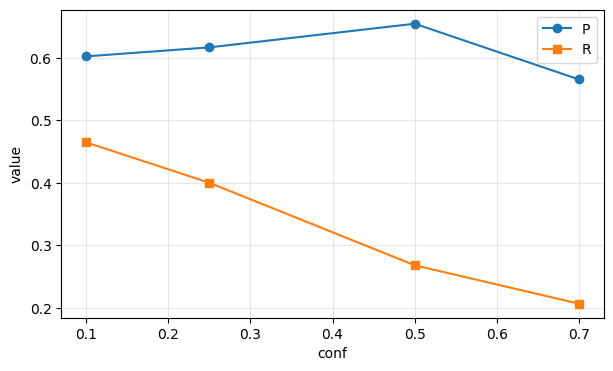

In [29]:
plt.figure(figsize=(7, 4))
plt.plot(confs, ps, 'o-', label='P')
plt.plot(confs, rs, 's-', label='R')
plt.xlabel('conf')
plt.ylabel('value')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

# SSDlite320

In [30]:
from torchvision.models.detection import ssdlite320_mobilenet_v3_large, SSDLite320_MobileNet_V3_Large_Weights

w = SSDLite320_MobileNet_V3_Large_Weights.DEFAULT
ssd = ssdlite320_mobilenet_v3_large(weights=w).eval()
pre = w.transforms()
cats = w.meta['categories']

def ssd_infer(path, conf=0.25):
    x = pre(Image.open(path).convert('RGB')).unsqueeze(0)
    with torch.no_grad():
        t = time.time()
        o = ssd(x)[0]
        dt = time.time() - t
    keep = o['scores'] > conf
    names = []
    for l in o['labels'][keep]:
        n = cats[int(l)]
        if n and n != '__background__':
            names.append(n)
    return names, dt

# Сравнение моделей

In [31]:
_ = model.predict(source=str(image_paths[0]), imgsz=IMG_SIZE, conf=CONF_THR, verbose=False)
_ = ssd_infer(image_paths[0])

test = image_paths[:5]
yd, yt, sd, st = {}, [], {}, []

for p in test:
    t = time.time()
    r = model.predict(source=str(p), imgsz=IMG_SIZE, conf=CONF_THR, verbose=False)[0]
    yt.append(time.time() - t)
    yd[p.name] = [model.names[int(c)] for c in r.boxes.cls] if len(r.boxes) else []

for p in test:
    n, dt = ssd_infer(p)
    sd[p.name] = n; st.append(dt)

yolo_ms = float(np.mean(yt) * 1000)
ssd_ms = float(np.mean(st) * 1000)
print('yolo avg ms', round(yolo_ms, 1))
print('ssd avg ms', round(ssd_ms, 1))
print()

cmp_rows = []
for p in test:
    a = yd[p.name]; b = sd[p.name]
    common = set(a) & set(b)
    cmp_rows.append({
        'image': p.name,
        'yolo_n': len(a), 'ssd_n': len(b),
        'yolo_classes': ', '.join(sorted(a)),
        'ssd_classes': ', '.join(sorted(b)),
        'common_classes': ', '.join(sorted(common)),
        'jaccard': round(len(common) / len(set(a) | set(b)), 3) if (a or b) else None,
    })
cmp_table = pd.DataFrame(cmp_rows)
cmp_table

yolo avg ms 10.0
ssd avg ms 35.8



,image,yolo_n,ssd_n,yolo_classes,ssd_classes,common_classes,jaccard
0,01_bus.jpg,4,5,"bus, person, person, person","bus, person, person, person, person","bus, person",1.0
1,02_zidane.jpg,2,2,"person, person","person, person",person,1.0
2,03_dog.jpg,1,1,dog,dog,dog,1.0
3,04_cat.jpg,2,1,"cat, cat",cat,cat,1.0
4,05_car.jpg,1,1,car,car,car,1.0


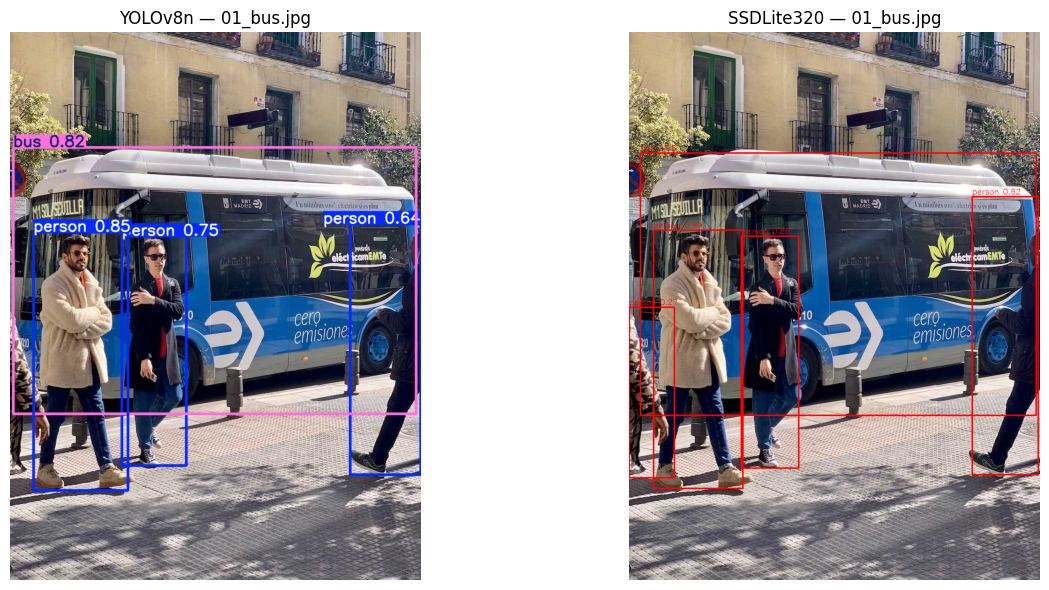

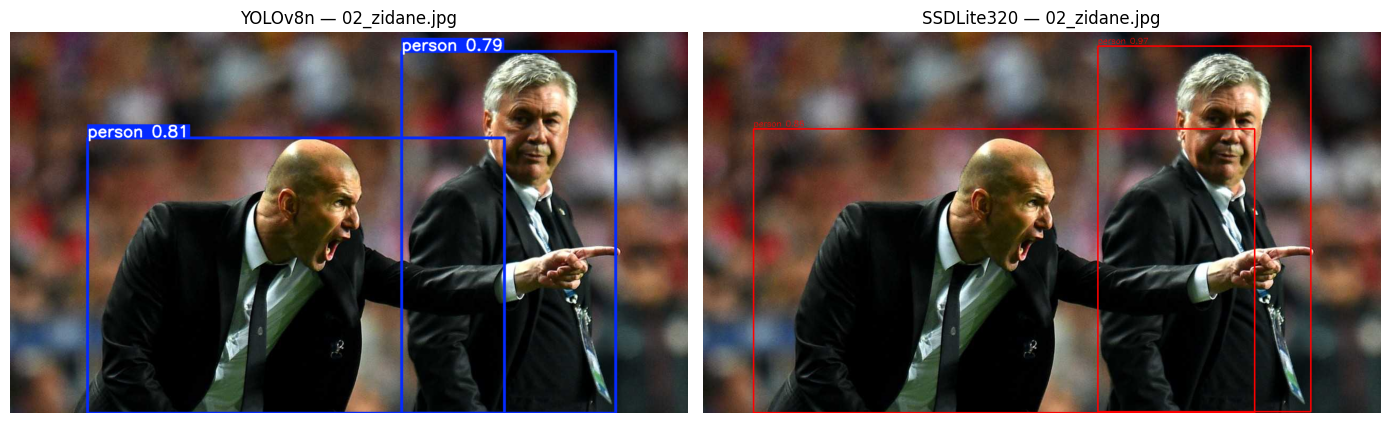

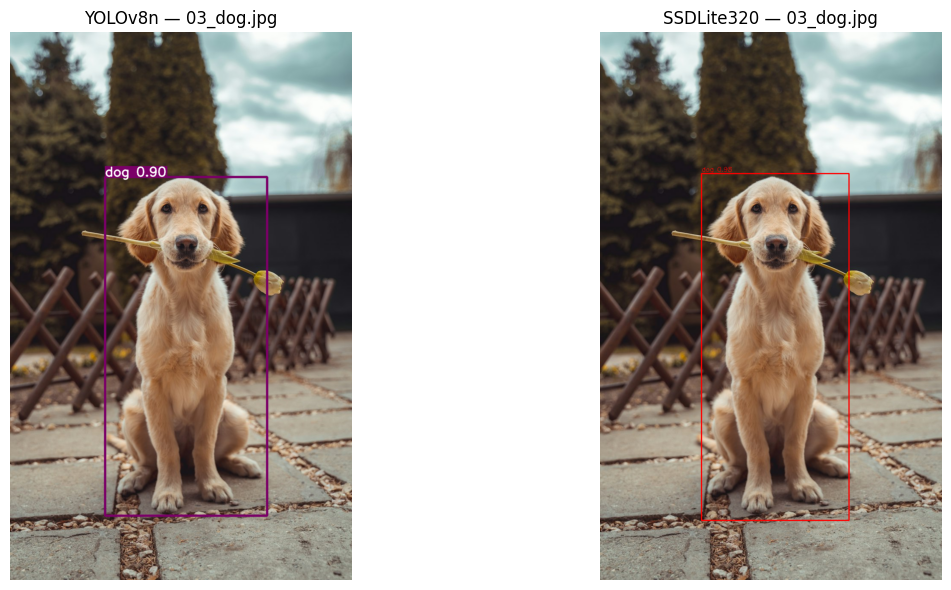

In [32]:
for p in test[:3]:
    r = model.predict(source=str(p), imgsz=IMG_SIZE, conf=CONF_THR, verbose=False)[0]
    yolo_vis = r.plot()[:, :, ::-1]

    pil = Image.open(p).convert('RGB')
    x = pre(pil).unsqueeze(0)
    with torch.no_grad():
        o = ssd(x)[0]
    keep = o['scores'] > CONF_THR
    ssd_vis = np.array(pil).copy()
    for b, s, l in zip(o['boxes'][keep], o['scores'][keep], o['labels'][keep]):
        name = cats[int(l)]
        if name == '__background__':
            continue
        x1, y1, x2, y2 = map(int, b.tolist())
        cv2.rectangle(ssd_vis, (x1, y1), (x2, y2), (255, 0, 0), 2)
        cv2.putText(ssd_vis, f'{name} {s:.2f}', (x1, max(y1 - 5, 12)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 1)

    fig, ax = plt.subplots(1, 2, figsize=(14, 6))
    ax[0].imshow(yolo_vis); ax[0].set_title(f'YOLOv8n — {p.name}'); ax[0].axis('off')
    ax[1].imshow(ssd_vis);  ax[1].set_title(f'SSDLite320 — {p.name}'); ax[1].axis('off')
    plt.tight_layout()
    plt.show()